# Relatório da Modelagem

**Universidade Estadual de Montes Claros**  
**Especialização em Ciência de Dados**  
**Disciplina:** Trabalho de Conclusão de Curso  
**Aluno:** Luan Silva Gomes  

**Projeto:** Predizer a gravidade de acidentes de trânsito com vítimas em Minas Gerais utilizando dados de 2016 a 2025, provenientes da Base de Dados do Painel de Sinistro de Trânsito da Secretaria de Estado de Justiça e Segurança Pública de Minas Gerais, para que o socorro médico possa ser direcionado/priorizado com mais eficiência na resposta da emergência.

Este notebook dá sequência à análise exploratória (`eda.ipynb` e `eda_10_years.ipynb`) e reúne a seleção de atributos, o treinamento dos modelos e a comparação entre os recortes temporais de 5 e de 10 anos.

# Importação de Dependências e Configurações Básicas

Os dados brutos estão armazenados no diretório `/data` deste projeto. Além das bibliotecas já utilizadas na análise exploratória, esta etapa utiliza o scikit-learn e o XGBoost.

In [1]:
import sys
import os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.exists() or not DATA_DIR.is_dir():
     raise FileNotFoundError(f"Diretório de dados '{DATA_DIR}' não encontrado")

In [2]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold

from src.constants import (
    TEN_YEARS,
    TEST_YEAR,
    TRAIN_YEARS_5,
    TRAIN_YEARS_10,
    CANDIDATE_FEATURES,
    RANDOM_STATE
)

pd.set_option('display.max_colwidth', None)

# Preparação dos Dados

## 1. Base analítica

Nesta etapa, a base analítica é construída com as mesmas funções da análise exploratória, porém com os 10 anos de dados (2016 a 2025), para que os dois recortes sejam avaliados no mesmo conjunto de teste. Diferentemente da análise exploratória, a função `clean_missing_values` é chamada com `impute=False`, pois os valores faltantes são imputados dentro do pipeline de cada modelo, apenas com os dados de treino. Os registros sem coordenadas também são mantidos, já que latitude e longitude não são utilizadas como atributos.

In [3]:
from src.preprocessing import (
    get_df_per_data_group,
    build_analytical_base_table,
    apply_filters,
    clean_missing_values
)

df_per_data_group = get_df_per_data_group(DATA_DIR, TEN_YEARS)
df_final_abt = build_analytical_base_table(
    df_ocorrencias=df_per_data_group['ocorrencias'],
    df_vitimas=df_per_data_group['vitimas'],
    df_condicoes=df_per_data_group['condicoes'],
    df_via=df_per_data_group['via'],
    df_veiculos=df_per_data_group['veiculo'],
)
filtered_df = apply_filters(df_final_abt, TEN_YEARS)
df_modelo = clean_missing_values(filtered_df, drop_missing_coordinates=False, impute=False)
print(f"Instâncias disponíveis para a modelagem: {len(df_modelo)}")

/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:18: DtypeWarning: Columns (0: oco_latitude_sirgas2000, 1: oco_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)
/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:18: DtypeWarning: Columns (0: vit_latitude_sirgas2000, 1: vit_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)


1/4. Processando tabela base de ocorrências...
   -> Tabela base pronta com 2665653 ocorrências únicas.

2/4. Agrupando datasets secundários...
   -> Agrupamentos concluídos.

3/4. Realizando merges (LEFT JOINs)...
   -> Validação concluída: Nenhuma duplicata gerada no merge.

ABT gerada com sucesso! Dimensões finais: 2665653 linhas x 42 colunas.

Instâncias disponíveis para a modelagem: 650086


## 2. Divisão em treino e teste

In [4]:
from src.modeling import split_train_test_by_year, get_features_and_target

df_treino_5, df_teste = split_train_test_by_year(df_modelo, TRAIN_YEARS_5, TEST_YEAR)
df_treino_10, _ = split_train_test_by_year(df_modelo, TRAIN_YEARS_10, TEST_YEAR)

print("\nPercentual de acidentes graves por ano:")
display((df_modelo.groupby('oco_ano_fato')['acidente_grave'].mean() * 100).round(2).to_frame().T)

Treino (2021-2024): 245310 instâncias | 18.05% de acidentes graves
Teste (2025): 64643 instâncias | 16.41% de acidentes graves
Treino (2016-2024): 585443 instâncias | 18.02% de acidentes graves
Teste (2025): 64643 instâncias | 16.41% de acidentes graves

Percentual de acidentes graves por ano:


oco_ano_fato,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
acidente_grave,18.25,18.17,17.95,17.54,18.03,17.95,18.01,18.63,17.58,16.41


A divisão entre treino e teste é temporal. O ano de 2025 é o conjunto de teste nos dois recortes, e os modelos são treinados com os dados de 2021 a 2024, no recorte de 5 anos, ou de 2016 a 2024, no recorte de 10 anos, de modo que são avaliados em um ano que não participou do treinamento. A função `split_train_test_by_year` também garante que nenhuma ocorrência apareça ao mesmo tempo no treino e no teste.

Após a divisão, o conjunto de teste ficou com 64.643 acidentes, sendo 16,41% de ocorrências graves. Já os treinos dos recortes de 5 e 10 anos possuem 245.310 e 585.443 acidentes, respectivamente, ambos com cerca de 18% de graves.

# Seleção de Atributos

Nesta seção, a seleção de atributos é feita em quatro etapas:
1. Variância, para identificar atributos praticamente constantes.
2. Correlação de Pearson e F-score (ANOVA) de cada atributo com a variável alvo.
3. Identificação de atributos redundantes.
4. Análise das combinações, avaliando o desempenho com os k atributos de maior F-score.

Todas as etapas utilizam apenas o treino do recorte de 5 anos (2021 a 2024), que faz parte dos dois recortes, e a lista final de atributos é usada em ambos.

## 1. Atributos candidatos

Das 41 colunas da base filtrada, foram mantidos como candidatos os 32 atributos numéricos e binários construídos no pré-processamento (`CANDIDATE_FEATURES` em `/src/constants.py`). Ficaram de fora:
- `numero_ocorrencia_associado` e `acidente_grave`: Identificador da ocorrência e variável alvo.
- `oco_ano_fato`: O ano de teste (2025) não existe no treino.
- `oco_natureza_descricao`: Após o filtro de acidentes com vítimas, praticamente todos os registros têm o mesmo valor (99,96% no treino).
- `oco_nome_municipio`, `oco_nome_bairro` e `oco_tipo_logradouro_descricao`: Textos com muitas categorias.
- `oco_latitude_sirgas2000` e `oco_longitude_sirgas2000`: Estão em formato de texto e têm mais valores faltantes.

In [5]:
colunas_fora = [col for col in df_modelo.columns if col not in CANDIDATE_FEATURES]
print(f"Colunas da base filtrada: {df_modelo.shape[1]} | atributos candidatos: {len(CANDIDATE_FEATURES)}")
print(f"Colunas que não são candidatas: {colunas_fora}")

print("\nPercentual de cada natureza no treino (2021-2024):")
display((df_treino_5['oco_natureza_descricao'].value_counts(normalize=True) * 100).round(2))

print("\nQuantidade de categorias no treino (2021-2024):")
display(df_treino_5[['oco_nome_municipio', 'oco_nome_bairro', 'oco_tipo_logradouro_descricao']].nunique())

coordenadas = ['oco_latitude_sirgas2000', 'oco_longitude_sirgas2000']
print("\nTipo das colunas de coordenadas:")
print(df_modelo[coordenadas].dtypes)

print("\nPercentual de registros sem coordenadas por ano:")
display((df_modelo[coordenadas].isna().groupby(df_modelo['oco_ano_fato']).mean() * 100).round(2).T)

Colunas da base filtrada: 41 | atributos candidatos: 32
Colunas que não são candidatas: ['numero_ocorrencia_associado', 'oco_ano_fato', 'oco_tipo_logradouro_descricao', 'oco_natureza_descricao', 'oco_nome_bairro', 'oco_nome_municipio', 'oco_latitude_sirgas2000', 'oco_longitude_sirgas2000', 'acidente_grave']

Percentual de cada natureza no treino (2021-2024):


oco_natureza_descricao
ACIDENTE DE TRANSITO COM VITIMA    99.96
ACIDENTE DE TRANSITO SEM VITIMA     0.04
Name: proportion, dtype: float64


Quantidade de categorias no treino (2021-2024):


oco_nome_municipio                853
oco_nome_bairro                  7501
oco_tipo_logradouro_descricao     130
dtype: int64


Tipo das colunas de coordenadas:
oco_latitude_sirgas2000     str
oco_longitude_sirgas2000    str
dtype: object

Percentual de registros sem coordenadas por ano:


oco_ano_fato,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
oco_latitude_sirgas2000,13.02,12.5,13.0,12.08,11.25,8.15,6.73,4.16,0.85,1.0
oco_longitude_sirgas2000,13.02,12.5,13.0,12.08,11.25,8.15,6.73,4.16,0.85,1.0


In [6]:
X_treino_5, y_treino_5 = get_features_and_target(df_treino_5, CANDIDATE_FEATURES)
print(f"Atributos candidatos: {X_treino_5.shape[1]}")
print(f"Instâncias de treino usadas na seleção: {X_treino_5.shape[0]}")

Atributos candidatos: 32
Instâncias de treino usadas na seleção: 245310


## 2. Variância

In [7]:
from src.modeling import compute_features_variance

display(compute_features_variance(X_treino_5).round(4))

,atributo,tipo,variancia,coef_variacao,percentual_valor_1
0,qtd_defeitos_via,numérico,0.1611,3.7557,NaN
1,qtd_veiculos_envolvidos,numérico,0.3890,0.3745,NaN
2,qtd_vitimas,numérico,0.5332,0.5790,NaN
3,hora_fato,numérico,30.0632,0.3978,NaN
4,idade_media_vitimas,numérico,207.8208,0.4145,NaN
5,idade_maxima_vitima,numérico,236.0801,0.4230,NaN
6,has_via_sulcos_horizontais,binário,0.0055,NaN,0.5499
7,has_material_na_pista,binário,0.0055,NaN,0.5544
8,has_via_rachadura,binário,0.0113,NaN,1.1439
9,has_registro_veiculo,binário,0.0155,NaN,98.4301


Variância muito baixa indica que um atributo possui quase sempre o mesmo valor e pouco contribui para identificar se um acidente é grave ou não. Como a variância depende da unidade de medida, a tabela também mostra o coeficiente de variação (desvio padrão dividido pela média) dos atributos numéricos e, para os binários, o percentual de valores 1.

Nenhum atributo numérico apresenta variância próxima de zero. Os coeficientes de variação estão entre 0,37 (`qtd_veiculos_envolvidos`) e 3,76 (`qtd_defeitos_via`). Entre os binários, os menos frequentes são `has_via_sulcos_horizontais` e `has_material_na_pista` (0,55% dos acidentes) e `has_via_rachadura` (1,14%). Contudo, nesses casos, a variância baixa reflete apenas a raridade do evento. O atributo `is_noite_sem_iluminacao`, por exemplo, ocorre em apenas 4,98% dos acidentes e é o de maior correlação com a gravidade. Por isso, o critério de variância foi aplicado somente aos atributos numéricos, e nenhum atributo foi descartado nesta etapa.

## 3. Correlação de Pearson com a variável alvo

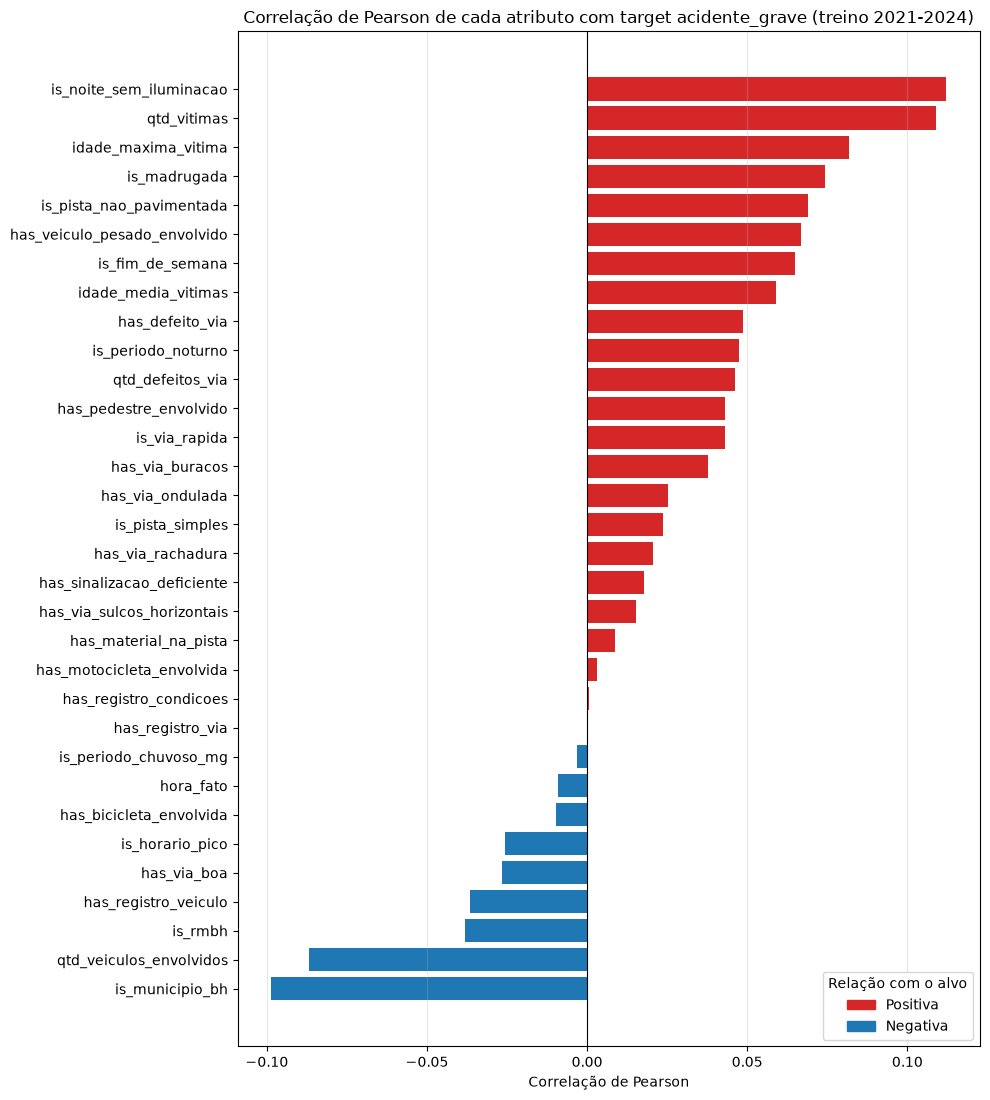

In [8]:
from src.modeling import compute_feature_relevance
from src.visualization import plot_scores_atributos

relevancia = compute_feature_relevance(X_treino_5, y_treino_5)
plot_scores_atributos(relevancia['pearson'], 'Correlação de Pearson de cada atributo com target acidente_grave (treino 2021-2024)', 'Correlação de Pearson')

A correlação de Pearson mede a força e a direção da relação linear entre cada atributo e a variável alvo. As maiores correlações positivas são as de:
- `is_noite_sem_iluminacao`
- `qtd_vitimas`
- `idade_maxima_vitima`

Já as maiores negativas são as de:
- `is_municipio_bh`
- `qtd_veiculos_envolvidos`

Em módulo, os valores são baixos, o que também já havia sido observado no heatmap da análise exploratória.

## 4. F-score (ANOVA)

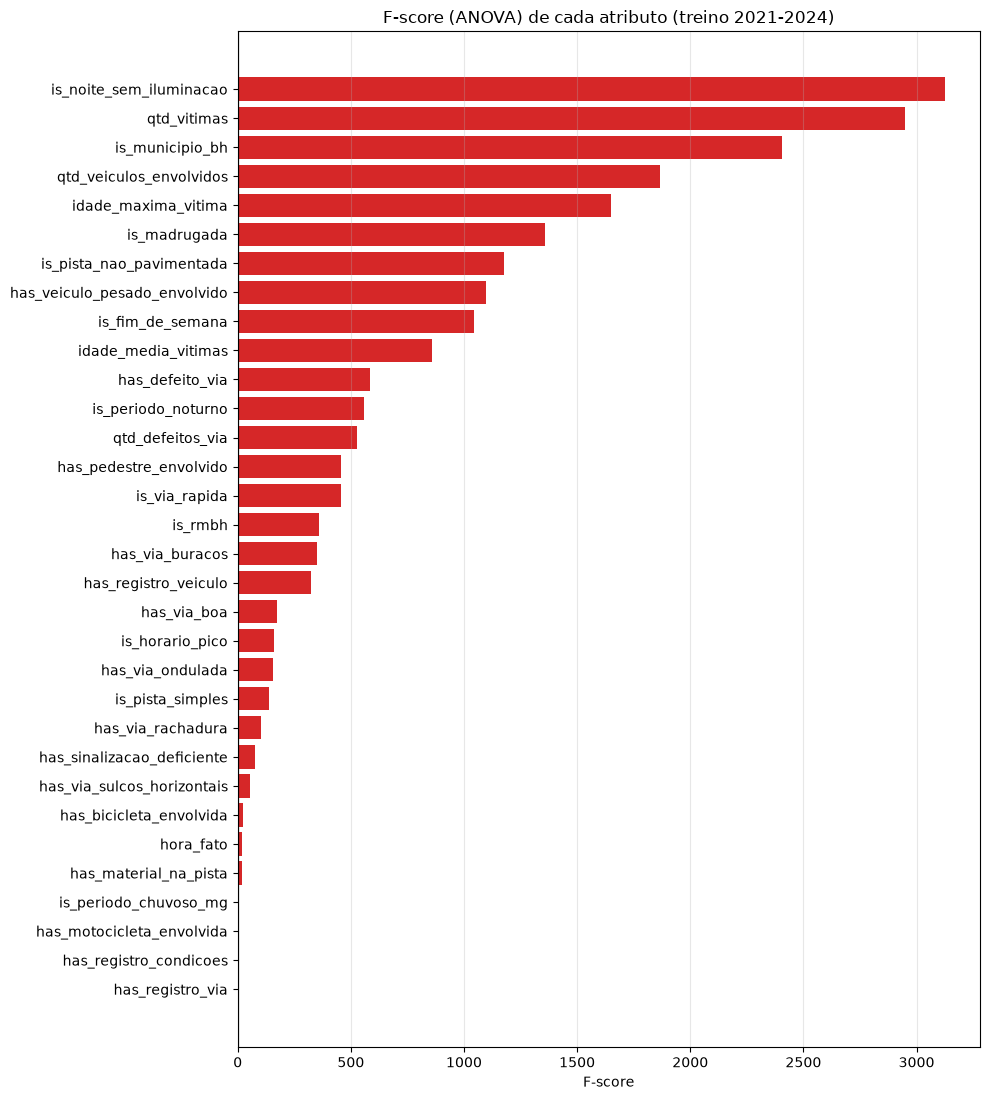

,pearson,abs_pearson,f_score,p_valor
atributo,,,,
is_noite_sem_iluminacao,0.1121,0.1121,3124.1895,0.0000
qtd_vitimas,0.1090,0.1090,2947.6476,0.0000
is_municipio_bh,-0.0986,0.0986,2405.8769,0.0000
qtd_veiculos_envolvidos,-0.0869,0.0869,1868.3365,0.0000
idade_maxima_vitima,0.0817,0.0817,1649.4825,0.0000
is_madrugada,0.0742,0.0742,1357.4259,0.0000
is_pista_nao_pavimentada,0.0691,0.0691,1176.6197,0.0000
has_veiculo_pesado_envolvido,0.0667,0.0667,1097.3171,0.0000
is_fim_de_semana,0.0651,0.0651,1042.5025,0.0000


In [9]:
plot_scores_atributos(relevancia['f_score'], 'F-score (ANOVA) de cada atributo (treino 2021-2024)', 'F-score')
display(relevancia.round(4))

In [11]:
ranking_f_score = relevancia.index.tolist()
ranking_pearson = relevancia.sort_values('abs_pearson', ascending=False).index.tolist()
print(f"O ranking pelo F-score é igual ao ranking pelo módulo da correlação de Pearson? -> {ranking_f_score == ranking_pearson}")

print("\nPercentual de acidentes graves por hora do fato (treino 2021-2024):")
display((df_treino_5.groupby('hora_fato')['acidente_grave'].mean() * 100).round(1).to_frame().T)

O ranking pelo F-score é igual ao ranking pelo módulo da correlação de Pearson? -> True

Percentual de acidentes graves por hora do fato (treino 2021-2024):


hora_fato,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
acidente_grave,30.8,25.8,28.3,28.7,31.2,27.0,20.7,14.8,13.5,15.1,...,16.5,16.8,18.0,17.5,18.4,18.8,19.7,20.3,20.4,22.7


O F-score, calculado pela função `f_classif`, mede o quanto a média do atributo nos acidentes graves se afasta da média nos não graves, em relação à dispersão dentro de cada grupo. O ranking obtido por ele é idêntico ao ranking pelo módulo da correlação de Pearson.

Contudo, as duas medidas captam apenas relações lineares. Por exemplo: a proporção de graves é de 30,8% à meia-noite, cai para 13,5% às 8h e volta a subir até 22,7% às 23h. Assim, `hora_fato` fica com correlação de apenas -0,009. Consequentemente, um F-score baixo não é motivo suficiente para descartar um atributo.

## 5. Atributos redundantes

In [12]:
from src.modeling import find_high_correlation_pairs

display(find_high_correlation_pairs(X_treino_5, threshold=0.85))

,atributo_1,atributo_2,correlacao
0,has_registro_condicoes,has_registro_via,0.985893
1,idade_media_vitimas,idade_maxima_vitima,0.953982
2,qtd_defeitos_via,has_defeito_via,0.877077
3,has_via_boa,has_registro_via,0.858193


In [13]:
print(f"Correlação entre has_via_boa e has_registro_condicoes: {X_treino_5['has_via_boa'].corr(X_treino_5['has_registro_condicoes']):.3f}")

Correlação entre has_via_boa e has_registro_condicoes: 0.849


Como manter os dois atributos de um par redundante não acrescenta informação e dificulta a interpretação dos coeficientes dos modelos lineares, a função `find_high_correlation_pairs` foi utilizada para listar os pares com correlação, em módulo, igual ou superior a 0,85 no treino. Foram encontrados quatro pares. Em cada um deles, descartou-se o atributo de menor F-score:
- `has_registro_condicoes` e `has_registro_via` (correlação = 0,986): descartou-se `has_registro_via`.
- `idade_media_vitimas` e `idade_maxima_vitima` (correlação = 0,954): descartou-se `idade_media_vitimas`.
- `qtd_defeitos_via` e `has_defeito_via` (correlação = 0,877): descartou-se `qtd_defeitos_via`.
- `has_via_boa` e `has_registro_via` (correlação = 0,858): descartou-se `has_registro_via`.

O par `has_via_boa` e `has_registro_condicoes` (correlação = 0,849) foi mantido. A correlação alta ocorre porque `has_via_boa` só vale 1 quando há registro da via, que quase sempre coincide com o registro de condições. Juntos, os dois distinguem ocorrência sem registro, via que não está em boas condições e via em boas condições.

In [14]:
atributos_redundantes = ['has_registro_via', 'idade_media_vitimas', 'qtd_defeitos_via']
FEATURES = [col for col in CANDIDATE_FEATURES if col not in atributos_redundantes]

X_treino_5, y_treino_5 = get_features_and_target(df_treino_5, FEATURES)
X_treino_10, y_treino_10 = get_features_and_target(df_treino_10, FEATURES)
X_teste, y_teste = get_features_and_target(df_teste, FEATURES)
print(f"Atributos mantidos após análise de redundância: {len(FEATURES)}")

Atributos mantidos após análise de redundância: 29


## 6. Análise das combinações: desempenho por número de atributos

Por fim, os atributos são ordenados pelo F-score e, para cada k entre 1 e 29, um modelo é treinado apenas com os k primeiros, medindo-se a PR-AUC (área sob a curva de precisão e recall) por validação cruzada. O `SelectKBest` fica dentro do pipeline, de modo que o ranking é recalculado apenas com os dados de treino de cada parte. A análise foi feita com a Regressão Logística e o HistGradientBoosting, representando, respectivamente, os modelos lineares e os baseados em árvores. A coluna `atributo_adicionado` indica o atributo que entra em cada k.

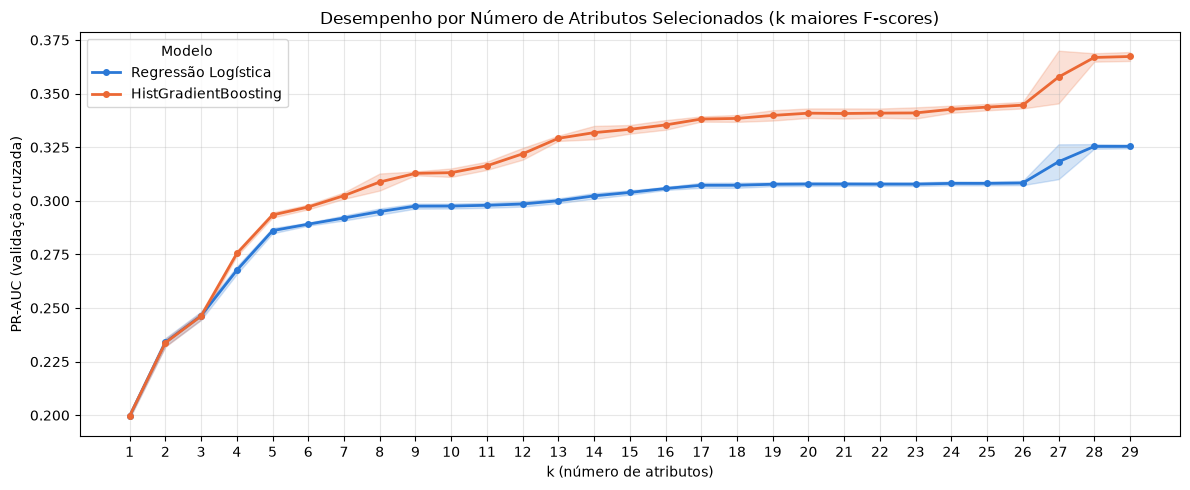

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from src.modeling import evaluate_k_best_features
from src.visualization import plot_desempenho_por_k

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

desempenho_k_lr = evaluate_k_best_features(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    X_treino_5, y_treino_5, cv, scale=True, n_jobs=-1
)
desempenho_k_hgb = evaluate_k_best_features(
    HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    X_treino_5, y_treino_5, cv, n_jobs=-1
)
plot_desempenho_por_k({'Regressão Logística': desempenho_k_lr, 'HistGradientBoosting': desempenho_k_hgb})

In [16]:
desempenho_k = desempenho_k_lr.merge(desempenho_k_hgb, on=['k', 'atributo_adicionado'], suffixes=('_lr', '_hgb'))
display(desempenho_k.round(4))

,k,atributo_adicionado,pr_auc_media_lr,pr_auc_desvio_lr,pr_auc_media_hgb,pr_auc_desvio_hgb
0,1,is_noite_sem_iluminacao,0.1997,0.0010,0.1997,0.0010
1,2,qtd_vitimas,0.2340,0.0019,0.2338,0.0018
2,3,is_municipio_bh,0.2464,0.0019,0.2462,0.0017
3,4,qtd_veiculos_envolvidos,0.2676,0.0018,0.2754,0.0012
4,5,idade_maxima_vitima,0.2861,0.0012,0.2934,0.0012
5,6,is_madrugada,0.2891,0.0007,0.2971,0.0011
6,7,is_pista_nao_pavimentada,0.2920,0.0012,0.3024,0.0015
7,8,has_veiculo_pesado_envolvido,0.2950,0.0014,0.3088,0.0040
8,9,is_fim_de_semana,0.2975,0.0012,0.3128,0.0009
9,10,has_defeito_via,0.2976,0.0012,0.3131,0.0020


In [17]:
from sklearn.model_selection import cross_val_score
from src.modeling import build_model_pipeline

top_26 = desempenho_k_lr['atributo_adicionado'].iloc[:26].tolist()
modelos_k = {
    'regressao_logistica': (LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE), True),
    'hist_gradient_boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE), False),
}

linhas = []
for atributo_extra in [None, 'is_periodo_chuvoso_mg', 'has_motocicleta_envolvida']:
    colunas = top_26 + ([atributo_extra] if atributo_extra else [])
    linha = {'atributos': '26 primeiros' + (f' + {atributo_extra}' if atributo_extra else '')}
    for nome, (modelo, scale) in modelos_k.items():
        scores = cross_val_score(build_model_pipeline(modelo, scale), X_treino_5[colunas], y_treino_5, cv=cv, scoring='average_precision', n_jobs=-1)
        linha[f'pr_auc_{nome}'] = scores.mean()
    linhas.append(linha)

print("PR-AUC (validação cruzada) com os 26 primeiros atributos do ranking e com cada um dos dois atributos seguintes:")
display(pd.DataFrame(linhas).set_index('atributos').round(4))

PR-AUC (validação cruzada) com os 26 primeiros atributos do ranking e com cada um dos dois atributos seguintes:


,pr_auc_regressao_logistica,pr_auc_hist_gradient_boosting
atributos,,
26 primeiros,0.3083,0.3446
26 primeiros + is_periodo_chuvoso_mg,0.3083,0.3443
26 primeiros + has_motocicleta_envolvida,0.3254,0.3670


Nos dois modelos, a PR-AUC cresce rapidamente com os primeiros atributos. Entre k = 17 e k = 26, a Regressão Logística praticamente se estabiliza, enquanto o HistGradientBoosting continua melhorando aos poucos.

Depois dos primeiros atributos, o maior salto ocorre com a entrada de `has_motocicleta_envolvida`, um dos atributos de menor F-score. Adicionado aos 26 primeiros, ele eleva a PR-AUC de 0,3083 para 0,3254 na Regressão Logística e de 0,3446 para 0,3670 no HistGradientBoosting.

Como nenhum dos dois modelos perde desempenho com os 29 atributos, nenhum atributo foi descartado nesta etapa. Dessa forma, o conjunto final é formado pelos 29 atributos que restaram após a remoção dos redundantes, e o `SelectKBest` do pipeline permanece configurado com todos eles.

# Modelagem (treino de 5 anos: 2021 a 2024)

## 1. Estratégia de validação e métricas

Na primeira etapa, o baseline e os modelos lineares são comparados para escolher o melhor deles. Na segunda, os modelos não lineares são comparados com esse modelo, e os três melhores seguem como finalistas. O conjunto de teste (2025) só é utilizado depois dessas escolhas.
Observações:
- Como a base é desbalanceada (cerca de 18% dos acidentes do treino são graves), os modelos que permitem pesos por classe dão peso maior à classe grave (`class_weight='balanced'` ou, no XGBoost, `scale_pos_weight`), e os demais são treinados sem pesos. 
- Como métrica principal será utilizada a PR-AUC (`average_precision`) e a ROC-AUC é usada como complementar.

## 2. Etapa 1: baseline e modelos lineares

[Dummy (baseline)] PR-AUC = 0.1805 ± 0.0000 (0.0 min)
[Regressão Logística] PR-AUC = 0.3254 ± 0.0009 (0.1 min)
[LDA] PR-AUC = 0.3250 ± 0.0013 (0.0 min)
[Ridge] PR-AUC = 0.3226 ± 0.0006 (0.0 min)
[LinearSVC] PR-AUC = 0.3250 ± 0.0008 (0.1 min)
[SGD] PR-AUC = 0.3252 ± 0.0012 (0.2 min)
[Perceptron] PR-AUC = 0.2434 ± 0.0144 (0.1 min)
[Nearest Centroid] PR-AUC = 0.2944 ± 0.0010 (0.0 min)
[Naive Bayes (Bernoulli)] PR-AUC = 0.2900 ± 0.0005 (0.0 min)
[Naive Bayes (Multinomial)] PR-AUC = 0.2699 ± 0.0017 (0.0 min)
[Naive Bayes (Complement)] PR-AUC = 0.2699 ± 0.0017 (0.0 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
Regressão Logística,0.3254,0.0009,0.6885,0.0028,{'model__C': 0.001},5,0.1
SGD,0.3252,0.0012,0.6884,0.0029,"{'model__alpha': 0.01, 'model__loss': 'log_loss'}",8,0.2
LinearSVC,0.3250,0.0008,0.6881,0.0027,{'model__C': 0.001},4,0.1
LDA,0.3250,0.0013,0.6874,0.0028,{},1,0.0
Ridge,0.3226,0.0006,0.6865,0.0025,{'model__alpha': 1000},5,0.0
Nearest Centroid,0.2944,0.0010,0.6632,0.0017,{'model__shrink_threshold': 1.0},4,0.0
Naive Bayes (Bernoulli),0.2900,0.0005,0.6692,0.0028,{'model__alpha': 0.01},3,0.0
Naive Bayes (Multinomial),0.2699,0.0017,0.6286,0.0019,{'model__alpha': 0.01},3,0.0
Naive Bayes (Complement),0.2699,0.0017,0.6286,0.0019,{'model__alpha': 0.01},3,0.0


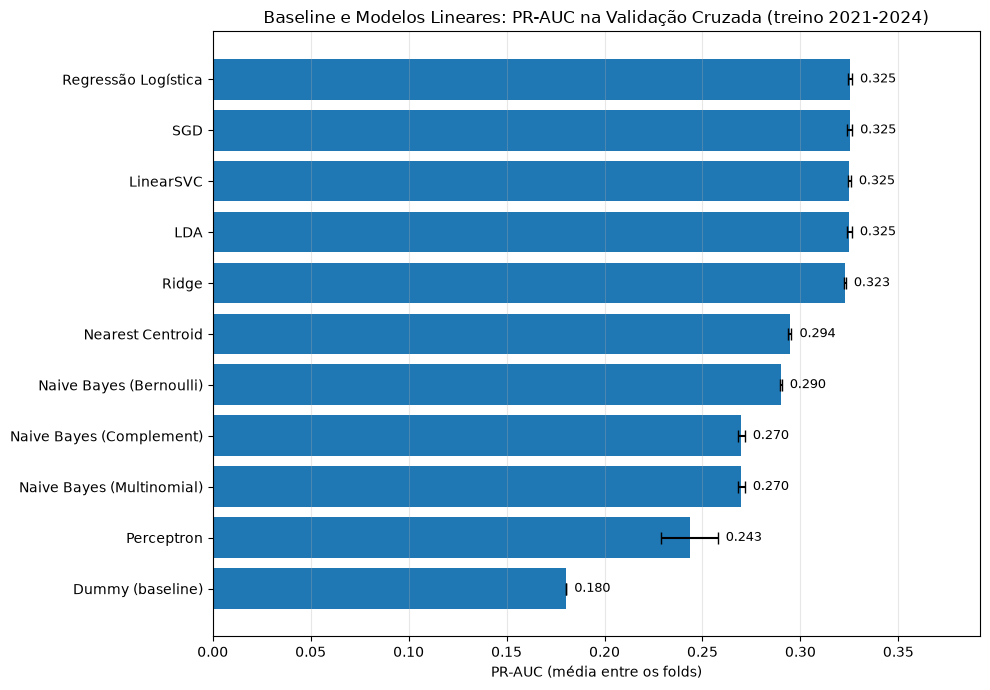

In [19]:
from src.modeling import get_linear_models, tune_models
from src.visualization import plot_comparacao_modelos

resultados_lineares_5, modelos_lineares_5 = tune_models(get_linear_models(), X_treino_5, y_treino_5, cv)
display(resultados_lineares_5.round(4))
plot_comparacao_modelos(resultados_lineares_5, titulo='Baseline e Modelos Lineares: PR-AUC na Validação Cruzada (treino 2021-2024)')

In [20]:
melhor_linear = resultados_lineares_5.drop(index='Dummy (baseline)').index[0]
print(f"Melhor modelo linear: {melhor_linear}")

Melhor modelo linear: Regressão Logística


Além do baseline, foram avaliados os classificadores lineares do scikit-learn viáveis nesta base. Por fim, todos os modelos lineares superam o baseline, cuja PR-AUC (0,1805) é igual à proporção de graves no treino. A Regressão Logística, o SGD, o LinearSVC e a LDA ficaram praticamente empatados, com diferença máxima de 0,0004 entre eles, seguidos pelo Ridge. Os demais ficaram bem abaixo, e o Perceptron teve o pior resultado e a maior variação entre as partições. Dessa forma, a Regressão Logística (C = 0,001) foi escolhida como o melhor modelo linear, por ter a maior PR-AUC média (0,3254).

## 3. Etapa 2: modelos não lineares

[HistGradientBoosting] PR-AUC = 0.3680 ± 0.0021 (0.8 min)
[Random Forest] PR-AUC = 0.3599 ± 0.0037 (3.3 min)
[XGBoost] PR-AUC = 0.3677 ± 0.0027 (0.5 min)
[Gradient Boosting] PR-AUC = 0.3675 ± 0.0018 (3.8 min)
[AdaBoost] PR-AUC = 0.3454 ± 0.0036 (2.5 min)
[Extra Trees] PR-AUC = 0.3588 ± 0.0045 (3.9 min)
[Bagging] PR-AUC = 0.3531 ± 0.0031 (4.4 min)
[Árvore de Decisão] PR-AUC = 0.3399 ± 0.0023 (0.1 min)
[Extra Tree] PR-AUC = 0.3121 ± 0.0080 (0.1 min)
[KNN] PR-AUC = 0.3393 ± 0.0054 (2.9 min)
[Radius Neighbors] PR-AUC = 0.3132 ± 0.0024 (1.5 min)
[MLP] PR-AUC = 0.3589 ± 0.0021 (3.4 min)
[QDA] PR-AUC = 0.2895 ± 0.0013 (0.1 min)
[Naive Bayes (Gaussiano)] PR-AUC = 0.2724 ± 0.0016 (0.0 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
HistGradientBoosting,0.3680,0.0021,0.7148,0.0039,"{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}",10,0.8
XGBoost,0.3677,0.0027,0.7142,0.0040,"{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_child_weight': 10, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}",10,0.5
Gradient Boosting,0.3675,0.0018,0.7138,0.0039,"{'model__subsample': 1.0, 'model__n_estimators': 100, 'model__min_samples_leaf': 50, 'model__max_depth': 5, 'model__learning_rate': 0.1}",10,3.8
Random Forest,0.3599,0.0037,0.7096,0.0041,"{'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': None}",10,3.3
MLP,0.3589,0.0021,0.7109,0.0032,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (50,)}",9,3.4
Extra Trees,0.3588,0.0045,0.7075,0.0041,"{'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 15}",10,3.9
Bagging,0.3531,0.0031,0.7075,0.0041,"{'model__max_samples': 0.5, 'model__estimator__min_samples_leaf': 50, 'model__estimator__max_depth': 15}",10,4.4
AdaBoost,0.3454,0.0036,0.7051,0.0040,"{'model__n_estimators': 100, 'model__learning_rate': 1.0, 'model__estimator__max_depth': 3}",10,2.5
Árvore de Decisão,0.3399,0.0023,0.6976,0.0041,"{'model__min_samples_leaf': 50, 'model__max_depth': 10}",10,0.1


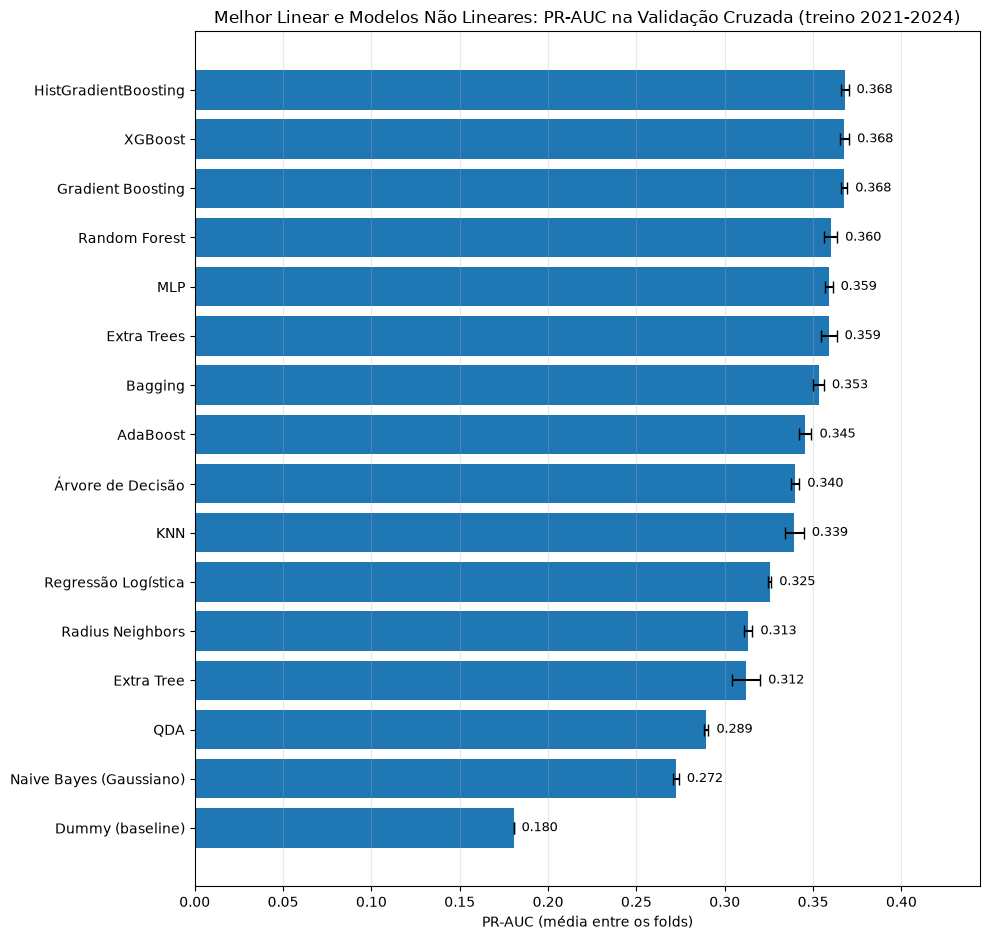

In [21]:
from src.modeling import get_nonlinear_models

scale_pos_weight_5 = (y_treino_5 == 0).sum() / (y_treino_5 == 1).sum()
resultados_nao_lineares_5, modelos_nao_lineares_5 = tune_models(get_nonlinear_models(scale_pos_weight_5), X_treino_5, y_treino_5, cv, n_iter=10)

resultados_5 = pd.concat([
    resultados_lineares_5.loc[['Dummy (baseline)', melhor_linear]],
    resultados_nao_lineares_5
]).sort_values('pr_auc_media', ascending=False)
display(resultados_5.round(4))
plot_comparacao_modelos(resultados_5, titulo='Melhor Linear e Modelos Não Lineares: PR-AUC na Validação Cruzada (treino 2021-2024)')

In [22]:
finalistas_nao_lineares = resultados_nao_lineares_5.index[:3].tolist()
print(f"Finalistas não lineares: {finalistas_nao_lineares}")

Finalistas não lineares: ['HistGradientBoosting', 'XGBoost', 'Gradient Boosting']


Na segunda etapa, foram avaliados 14 classificadores não lineares, comparados na tabela acima com o baseline e a Regressão Logística. Alguns classificadores do scikit-learn ficaram de fora por serem inviáveis com esse volume de dados (`SVC`, `NuSVC` e `GaussianProcessClassifier`) ou por não serem adequados a este problema (`LabelPropagation`, `LabelSpreading` e `CategoricalNB`). No Radius Neighbors, o maior raio testado foi 3, pois a memória necessária para a previsão aumenta rapidamente com o raio.

Os três modelos de gradient boosting ficaram à frente e praticamente empatados: HistGradientBoosting (0,3680), XGBoost (0,3677) e Gradient Boosting (0,3675). Em seguida aparecem a Random Forest, o MLP, a Extra Trees, o Bagging, o AdaBoost, a Árvore de Decisão e o KNN, todos acima da Regressão Logística (0,3254). Contudo, o Radius Neighbors, a Extra Tree, a QDA e o Naive Bayes gaussiano ficaram abaixo dela, ou seja, nem todo modelo não linear superou o modelo linear.

Em relação à Regressão Logística, o HistGradientBoosting teve um ganho de 0,0426 na PR-AUC, cerca de 13%. Assim, conforme a estratégia definida, os três modelos de gradient boosting seguem como finalistas para o teste, e o HistGradientBoosting, por ter a maior PR-AUC média, é usado como referência nas comparações.

## 4. Escolha do limiar de decisão

Os acidentes com score igual ou superior a um limiar são classificados como graves. Em vez do limiar padrão de 0,5, o limiar de cada modelo (baseline, Regressão Logística e finalistas) foi escolhido como o valor que maximiza o F1 da classe grave nas previsões fora da partição (`cross_val_predict`) do treino, sem utilizar o teste. Nos modelos treinados com pesos, o limiar escolhido fica próximo de 0,5. Já no Gradient Boosting, treinado sem pesos, ele fica em 0,20.

In [23]:
from src.modeling import find_best_threshold

modelos_finais_5 = {
    'Dummy (baseline)': modelos_lineares_5['Dummy (baseline)'],
    melhor_linear: modelos_lineares_5[melhor_linear],
    **{nome: modelos_nao_lineares_5[nome] for nome in finalistas_nao_lineares}
}

limiares_5 = {}
for nome, modelo in modelos_finais_5.items():
    limiar, f1_treino = find_best_threshold(modelo, X_treino_5, y_treino_5, cv)
    limiares_5[nome] = limiar
    print(f"[{nome}] limiar = {limiar:.4f} | F1 fora do fold = {f1_treino:.4f}")

[Dummy (baseline)] limiar = 0.1805 | F1 fora do fold = 0.3057
[Regressão Logística] limiar = 0.5103 | F1 fora do fold = 0.3935
[HistGradientBoosting] limiar = 0.5419 | F1 fora do fold = 0.4127
[XGBoost] limiar = 0.5449 | F1 fora do fold = 0.4121
[Gradient Boosting] limiar = 0.1992 | F1 fora do fold = 0.4120


## 5. Avaliação no conjunto de teste (2025)

,pr_auc,roc_auc,limiar,precisao,recall,f1,verdadeiros_positivos,falsos_positivos,falsos_negativos,verdadeiros_negativos
modelo,,,,,,,,,,
HistGradientBoosting,0.3447,0.7040,0.5419,0.2994,0.5166,0.3791,5480,12825,5128,41210
XGBoost,0.3446,0.7026,0.5449,0.3031,0.4970,0.3765,5272,12124,5336,41911
Gradient Boosting,0.3434,0.7025,0.1992,0.2941,0.5216,0.3762,5533,13278,5075,40757
Regressão Logística,0.3052,0.6773,0.5103,0.2690,0.5514,0.3616,5849,15891,4759,38144
Dummy (baseline),0.1641,0.5000,0.1805,0.1641,1.0000,0.2819,10608,54035,0,0


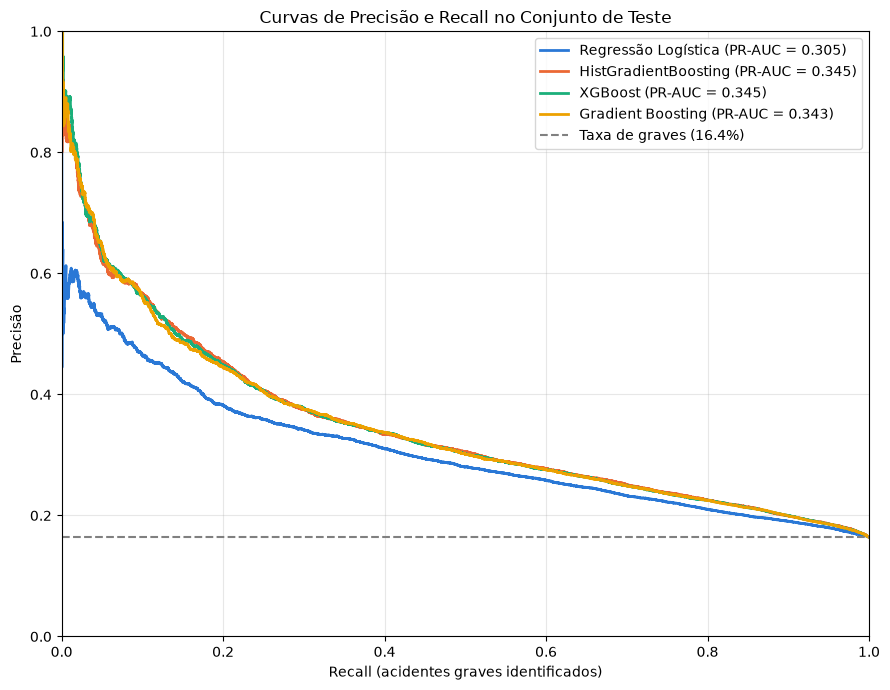

In [24]:
from src.modeling import evaluate_models_on_test
from src.visualization import plot_curvas_precisao_recall

metricas_teste_5, scores_teste_5 = evaluate_models_on_test(modelos_finais_5, limiares_5, X_teste, y_teste)
display(metricas_teste_5.round(4))
plot_curvas_precisao_recall(y_teste, {nome: scores for nome, scores in scores_teste_5.items() if nome != 'Dummy (baseline)'})

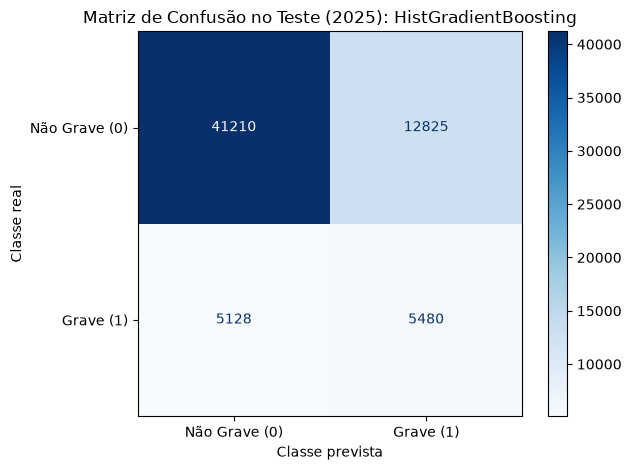

In [25]:
from src.visualization import plot_matriz_confusao

melhor_modelo_5 = resultados_5.index[0]
y_pred_melhor_5 = (scores_teste_5[melhor_modelo_5] >= limiares_5[melhor_modelo_5]).astype(int)
plot_matriz_confusao(y_teste, y_pred_melhor_5, titulo=f'Matriz de Confusão no Teste (2025): {melhor_modelo_5}')

In [26]:
from src.modeling import bootstrap_metric_ci, bootstrap_metric_difference

print("PR-AUC no teste com IC de 95% (bootstrap):")
display(pd.DataFrame({nome: bootstrap_metric_ci(y_teste, scores) for nome, scores in scores_teste_5.items()}).T.round(4))

comparacoes_5 = []
for nome, scores in scores_teste_5.items():
    if nome != melhor_modelo_5:
        diferenca = bootstrap_metric_difference(y_teste, scores_teste_5[melhor_modelo_5], scores)
        comparacoes_5.append({'comparacao': f'{melhor_modelo_5} - {nome}', **diferenca})

print(f"Diferença de PR-AUC no teste entre {melhor_modelo_5} e os demais modelos (bootstrap pareado):")
display(pd.DataFrame(comparacoes_5).set_index('comparacao').round(4))

PR-AUC no teste com IC de 95% (bootstrap):


,valor,ic_inferior,ic_superior
Dummy (baseline),0.1641,0.1613,0.1671
Regressão Logística,0.3052,0.2969,0.3138
HistGradientBoosting,0.3447,0.3361,0.3540
XGBoost,0.3446,0.3358,0.3538
Gradient Boosting,0.3434,0.3348,0.3525


Diferença de PR-AUC no teste entre HistGradientBoosting e os demais modelos (bootstrap pareado):


,diferenca,ic_inferior,ic_superior
comparacao,,,
HistGradientBoosting - Dummy (baseline),0.1806,0.1729,0.1889
HistGradientBoosting - Regressão Logística,0.0394,0.0337,0.0446
HistGradientBoosting - XGBoost,0.0001,-0.0016,0.0017
HistGradientBoosting - Gradient Boosting,0.0012,-0.0007,0.0031


A PR-AUC e a ROC-AUC não dependem do limiar, enquanto a precisão, o recall, o F1 e a matriz de confusão utilizam o limiar escolhido no treino. Para verificar se as diferenças não se devem ao acaso da amostra de teste, o intervalo de confiança de 95% da PR-AUC é calculado por bootstrap (1.000 reamostragens com reposição), e as comparações entre dois modelos utilizam o bootstrap pareado, com as mesmas reamostragens para os dois.

No teste, os finalistas ficam na seguinte ordem: HistGradientBoosting, XGBoost e Gradient Boosting, seguidos pela Regressão Logística e pelo baseline. Os valores são menores que os da validação cruzada, mas a PR-AUC depende da proporção de graves (16,41% em 2025 contra 18,05% no treino), enquanto a ROC-AUC, que não depende dela, varia menos.

O bootstrap pareado mostra que o HistGradientBoosting é superior à Regressão Logística. Já os intervalos das diferenças para o Gradient Boosting e para o XGBoost incluem o zero, ou seja, a diferença do HistGradientBoosting para os outros dois modelos de gradient boosting não é significativa.

# Comparação entre os Recortes de 5 e 10 Anos

Esta seção verifica se o recorte de 10 anos melhora a predição em relação ao de 5 anos. Para isso, o baseline, os modelos lineares e os três finalistas são ajustados novamente com os dados de 2016 a 2024, com os mesmos espaços de busca. Em seguida, o baseline, a Regressão Logística e os finalistas são avaliados no mesmo teste (2025). Os demais modelos não lineares não são reajustados, por terem ficado atrás dos finalistas no recorte de 5 anos.

## 1. Treino de 10 anos (2016 a 2024)

In [27]:
resultados_lineares_10, modelos_lineares_10 = tune_models(get_linear_models(), X_treino_10, y_treino_10, cv)
display(resultados_lineares_10.round(4))

scale_pos_weight_10 = (y_treino_10 == 0).sum() / (y_treino_10 == 1).sum()
candidatos_nao_lineares_10 = get_nonlinear_models(scale_pos_weight_10)
finalistas_10 = {nome: candidatos_nao_lineares_10[nome] for nome in finalistas_nao_lineares}
resultados_nao_lineares_10, modelos_nao_lineares_10 = tune_models(finalistas_10, X_treino_10, y_treino_10, cv, n_iter=10)
display(resultados_nao_lineares_10.round(4))


[Dummy (baseline)] PR-AUC = 0.1802 ± 0.0000 (0.1 min)
[Regressão Logística] PR-AUC = 0.3203 ± 0.0025 (0.2 min)
[LDA] PR-AUC = 0.3202 ± 0.0019 (0.1 min)
[Ridge] PR-AUC = 0.3178 ± 0.0024 (0.2 min)
[LinearSVC] PR-AUC = 0.3199 ± 0.0025 (0.3 min)
[SGD] PR-AUC = 0.3202 ± 0.0024 (0.4 min)
[Perceptron] PR-AUC = 0.2459 ± 0.0110 (0.2 min)
[Nearest Centroid] PR-AUC = 0.2910 ± 0.0008 (0.1 min)
[Naive Bayes (Bernoulli)] PR-AUC = 0.2853 ± 0.0011 (0.1 min)
[Naive Bayes (Multinomial)] PR-AUC = 0.2672 ± 0.0020 (0.1 min)
[Naive Bayes (Complement)] PR-AUC = 0.2672 ± 0.0020 (0.1 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
Regressão Logística,0.3203,0.0025,0.6845,0.0020,{'model__C': 0.001},5,0.2
LDA,0.3202,0.0019,0.6836,0.0019,{},1,0.1
SGD,0.3202,0.0024,0.6844,0.0020,"{'model__alpha': 0.01, 'model__loss': 'log_loss'}",8,0.4
LinearSVC,0.3199,0.0025,0.6842,0.0020,{'model__C': 0.001},4,0.3
Ridge,0.3178,0.0024,0.6830,0.0019,{'model__alpha': 1000},5,0.2
Nearest Centroid,0.2910,0.0008,0.6595,0.0016,{'model__shrink_threshold': 1.0},4,0.1
Naive Bayes (Bernoulli),0.2853,0.0011,0.6639,0.0017,{'model__alpha': 0.01},3,0.1
Naive Bayes (Multinomial),0.2672,0.0020,0.6266,0.0031,{'model__alpha': 0.01},3,0.1
Naive Bayes (Complement),0.2672,0.0020,0.6266,0.0031,{'model__alpha': 0.01},3,0.1


[HistGradientBoosting] PR-AUC = 0.3664 ± 0.0016 (2.1 min)
[XGBoost] PR-AUC = 0.3658 ± 0.0011 (1.3 min)
[Gradient Boosting] PR-AUC = 0.3657 ± 0.0016 (13.2 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
HistGradientBoosting,0.3664,0.0016,0.7126,0.0014,"{'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}",10,2.1
XGBoost,0.3658,0.0011,0.7118,0.0014,"{'model__subsample': 0.8, 'model__n_estimators': 400, 'model__min_child_weight': 10, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}",10,1.3
Gradient Boosting,0.3657,0.0016,0.7125,0.0017,"{'model__subsample': 0.8, 'model__n_estimators': 400, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__learning_rate': 0.1}",10,13.2


In [31]:
modelos_finais_10 = {
    'Dummy (baseline)': modelos_lineares_10['Dummy (baseline)'],
    melhor_linear: modelos_lineares_10[melhor_linear],
    **modelos_nao_lineares_10
}

limiares_10 = {}
for nome, modelo in modelos_finais_10.items():
    limiar, f1_treino = find_best_threshold(modelo, X_treino_10, y_treino_10, cv)
    limiares_10[nome] = limiar
    print(f"[{nome}] limiar = {limiar:.4f} | F1 fora do fold = {f1_treino:.4f}")

metricas_teste_10, scores_teste_10 = evaluate_models_on_test(modelos_finais_10, limiares_10, X_teste, y_teste)
display(metricas_teste_10.round(4))

[Dummy (baseline)] limiar = 0.1802 | F1 fora do fold = 0.3053
[Regressão Logística] limiar = 0.4972 | F1 fora do fold = 0.3884
[HistGradientBoosting] limiar = 0.5300 | F1 fora do fold = 0.4089
[XGBoost] limiar = 0.5321 | F1 fora do fold = 0.4078
[Gradient Boosting] limiar = 0.1957 | F1 fora do fold = 0.4083


,pr_auc,roc_auc,limiar,precisao,recall,f1,verdadeiros_positivos,falsos_positivos,falsos_negativos,verdadeiros_negativos
modelo,,,,,,,,,,
XGBoost,0.3488,0.7042,0.5321,0.3028,0.5029,0.3780,5335,12284,5273,41751
Gradient Boosting,0.3485,0.7050,0.1957,0.2985,0.5171,0.3785,5485,12889,5123,41146
HistGradientBoosting,0.3480,0.7048,0.5300,0.3004,0.5196,0.3807,5512,12838,5096,41197
Regressão Logística,0.3053,0.6770,0.4972,0.2663,0.5576,0.3605,5915,16294,4693,37741
Dummy (baseline),0.1641,0.5000,0.1802,0.1641,1.0000,0.2819,10608,54035,0,0


No recorte de 10 anos, a Regressão Logística continua sendo o melhor modelo linear (0,3203), e o HistGradientBoosting mantém a maior PR-AUC média entre os finalistas (0,3664), seguido de perto pelo XGBoost e pelo Gradient Boosting. Esses valores não devem ser comparados diretamente com os do recorte de 5 anos, pois as partições de validação contêm anos diferentes. Por isso, a comparação entre os recortes é feita no teste.

No teste, os três modelos de gradient boosting do recorte de 10 anos ficaram um pouco à frente das versões de 5 anos (no XGBoost, por exemplo, 0,3488 contra 0,3446), enquanto a Regressão Logística ficou praticamente igual (0,3053 contra 0,3052).

## 2. Comparação no mesmo conjunto de teste

,modelo,recorte,valor,ic_inferior,ic_superior
0,Regressão Logística,5 anos (2021-2024),0.3052,0.2969,0.3138
1,Regressão Logística,10 anos (2016-2024),0.3053,0.2970,0.3138
2,HistGradientBoosting,5 anos (2021-2024),0.3447,0.3361,0.3540
3,HistGradientBoosting,10 anos (2016-2024),0.3480,0.3393,0.3572
4,XGBoost,5 anos (2021-2024),0.3446,0.3358,0.3538
5,XGBoost,10 anos (2016-2024),0.3488,0.3401,0.3578
6,Gradient Boosting,5 anos (2021-2024),0.3434,0.3348,0.3525
7,Gradient Boosting,10 anos (2016-2024),0.3485,0.3397,0.3578


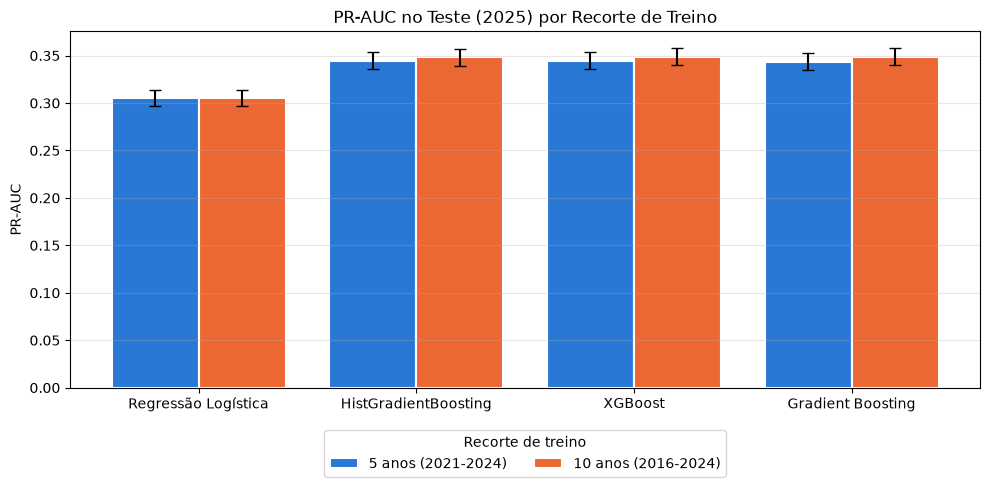

In [32]:
from src.visualization import plot_comparacao_recortes

modelos_comparados = [nome for nome in modelos_finais_5 if nome != 'Dummy (baseline)']

linhas = []
for nome in modelos_comparados:
    linhas.append({'modelo': nome, 'recorte': '5 anos (2021-2024)', **bootstrap_metric_ci(y_teste, scores_teste_5[nome])})
    linhas.append({'modelo': nome, 'recorte': '10 anos (2016-2024)', **bootstrap_metric_ci(y_teste, scores_teste_10[nome])})
comparacao_recortes = pd.DataFrame(linhas)
display(comparacao_recortes.round(4))
plot_comparacao_recortes(comparacao_recortes)

In [33]:
diferencas_recortes = []
for nome in modelos_comparados:
    diferenca = bootstrap_metric_difference(y_teste, scores_teste_10[nome], scores_teste_5[nome])
    diferencas_recortes.append({'modelo': nome, **diferenca})

print("Diferença de PR-AUC no teste (10 anos - 5 anos), com IC de 95% (bootstrap pareado):")
display(pd.DataFrame(diferencas_recortes).set_index('modelo').round(4))

Diferença de PR-AUC no teste (10 anos - 5 anos), com IC de 95% (bootstrap pareado):


,diferenca,ic_inferior,ic_superior
modelo,,,
Regressão Logística,0.0001,-0.0003,0.0005
HistGradientBoosting,0.0034,0.0013,0.0055
XGBoost,0.0043,0.0016,0.0069
Gradient Boosting,0.0050,0.0023,0.0077


Para cada modelo, a diferença de PR-AUC entre os dois recortes foi calculada por bootstrap pareado, nas mesmas 1.000 reamostragens do teste. O ganho do recorte de 10 anos é estatisticamente significativo nos três modelos de gradient boosting, já que nenhum dos intervalos de confiança inclui o zero, mas é pequeno: 0,0034 no HistGradientBoosting, 0,0043 no XGBoost e 0,0050 no Gradient Boosting. Na Regressão Logística, a diferença (0,0001) não é significativa. Portanto, a escolha do algoritmo, que separa a Regressão Logística dos modelos de gradient boosting em cerca de 0,04, teve impacto muito maior que a ampliação do histórico.

# Considerações Finais

Os principais resultados desta etapa foram:
1. Seleção de atributos: Apenas os três atributos redundantes foram removidos. A análise das combinações mostrou que o ranking individual precisa ser analisado com mais cautela, já que `has_motocicleta_envolvida`, um dos atributos de menor F-score, está entre os que mais contribuem para o desempenho.
2. Comparação entre modelos: Os três modelos de gradient boosting foram os melhores entre todos os avaliados. No teste, com o recorte de 5 anos, o HistGradientBoosting obteve PR-AUC de 0,3447, contra 0,3052 da Regressão Logística e 0,1641 do baseline, sem diferença significativa para o XGBoost e o Gradient Boosting.
3. Recortes temporais: O recorte de 10 anos trouxe um ganho pequeno, mas significativo, para os modelos de gradient boosting, e nenhum ganho significativo para a Regressão Logística.

Limitações:
- Parte dos atributos, como a quantidade e a idade das vítimas e as condições da via, vem do boletim de ocorrência e pode não estar disponível no momento do chamado.
- A proporção de graves em 2025 (16,41%) é menor que a dos anos de treino, o que dificulta a comparação direta entre as métricas do teste e as da validação cruzada.
- Os espaços de busca de hiperparâmetros foram limitados: nos modelos com mais de 10 combinações, foram testadas apenas 10 e, em vários modelos, inclusive na Regressão Logística, o melhor valor ficou no limite da grade testada.
- No recorte de 10 anos, apenas os finalistas não lineares foram reajustados.